## Support Vector Machine (SVM)

### Theorie

Een **Support Vector Machine** is een margin-based classificatiealgoritme. Waar KNN naar lokale buren kijkt en een Decision Tree de ruimte in rechthoeken opknipt, zoekt een SVM één **scheidingsvlak** dat de twee klassen van elkaar scheidt met de **grootst mogelijke marge**.

Voor een lineaire SVM is dat vlak:

$$
f(x) = w^\top x + b
$$

De voorspelling is het teken van $f(x)$: positief betekent klasse 1 (stroke), negatief klasse 0. De marge is de afstand tussen het vlak en de dichtstbijzijnde punten van beide klassen. Die dichtstbijzijnde punten heten de **support vectors**; zij zijn de enige observaties die de positie van het vlak bepalen. Alle andere punten mogen verschuiven zonder dat het model verandert. Dat maakt SVM relatief robuust tegen ruis ver van de beslissingsgrens, maar ook **zeer gevoelig voor de punten in het overlapgebied** en bij stroke-data ligt vrijwel alles in dat overlapgebied.

#### Hard margin, soft margin en de rol van C




In de praktijk zijn klassen nooit perfect scheidbaar. Daarom gebruikt een SVM een **soft margin**: punten mogen de marge in of zelfs aan de verkeerde kant terechtkomen, maar dat kost iets. Het optimalisatieprobleem wordt:

$$
\min_{w,b} \; \frac{1}{2}\lVert w \rVert^2 + C \sum_{i=1}^{n} \xi_i
$$

- $\lVert w \rVert^2$ is de regularisatieterm: hoe kleiner, hoe breder de marge.
- $\xi_i$ zijn de slack-variabelen: hoeveel observatie $i$ de marge schendt.
- $C$ bepaalt de afruil tussen beide.

$C$ is daarmee **de regularisatieparameter van de SVM**, maar werkt omgekeerd aan wat je gewend bent:

| Waarde van $C$ | Effect | Risico |
|---|---|---|
| **Laag** (bijv. 0,01) | Brede marge, veel fouten toegestaan, simpel model | Underfitting |
| **Hoog** (bijv. 100) | Smalle marge, model probeert elk trainingspunt goed te krijgen | Overfitting |

Let op: $C$ is de *inverse* van de regularisatiesterkte. Hoge $C$ = weinig regularisatie.

#### De kernel trick




Een rechte lijn is vaak te beperkt. De **kernel trick** lost dat op door de data impliciet naar een hoger-dimensionale ruimte te projecteren waar ze wél lineair scheidbaar is — zonder die ruimte ooit expliciet te berekenen. Alleen het inproduct tussen puntenparen wordt vervangen door een kernelfunctie $K(x_i, x_j)$.

| Kernel | Formule | Wanneer zinvol |
|---|---|---|
| `linear` | $K(x_i,x_j) = x_i^\top x_j$ | Veel features, bijna-lineaire samenhang, grote $n$ |
| `poly` | $K(x_i,x_j) = (\gamma\, x_i^\top x_j + r)^d$ | Interacties van vaste graad $d$ |
| `rbf` | $K(x_i,x_j) = \exp(-\gamma \lVert x_i - x_j \rVert^2)$ | Algemene niet-lineaire grenzen, standaardkeuze |
| `sigmoid` | $K(x_i,x_j)=\tanh(\gamma\, x_i^\top x_j + r)$ | Zelden beter dan RBF, overgeslagen |

De parameter $\gamma$ bij de RBF-kernel bepaalt hoe ver de invloed van één trainingspunt reikt:

- **Lage $\gamma$** → brede invloedssfeer → gladde, bijna lineaire grens → underfitting.
- **Hoge $\gamma$** → smalle invloedssfeer → elk punt bouwt zijn eigen eilandje → overfitting.

$C$ en $\gamma$ moeten daarom **samen** getuned worden; ze zijn niet onafhankelijk.

#### Waarom schalen bij SVM verplicht is



De RBF-kernel rekent met $\lVert x_i - x_j \rVert^2$ en de lineaire SVM met een gewichtsvector waarop één gezamenlijke regularisatie-norm $\lVert w \rVert^2$ wordt toegepast. In beide gevallen domineert een feature met een groot bereik automatisch het resultaat.

In onze dataset loopt `avg_glucose_level` van 55 tot 282 en `age` van 0,08 tot 82, terwijl alle dummykolommen 0 of 1 zijn. Zonder standaardisatie bepaalt glucose vrijwel in zijn eentje de afstand en worden `hypertension` en `heart_disease` effectief genegeerd. Dit is dezelfde reden als bij KNN, maar bij SVM is het effect nóg groter omdat ook de regularisatie scheef wordt getrokken. We gebruiken daarom `StandardScaler`, binnen een `Pipeline` zodat er geen datalekkage optreedt.

#### Waarom SVM geen kansen geeft



`SVC` levert standaard geen `predict_proba`. De uitvoer is een **decision function**: de getekende afstand tot het scheidingsvlak. Dat is geen kans, maar wel een monotone score, dus je kunt er prima een drempel op zetten — alleen ligt de neutrale drempel op **0,0** in plaats van 0,5.

Met `probability=True` schakelt scikit-learn **Platt scaling** in: een extra logistische regressie bovenop de decision function, gefit met interne 5-fold cross-validatie. Dat maakt het trainen ongeveer vijf keer zo duur en kan inconsistent zijn met `predict()`. Voor een dataset van deze omvang is dat niet verantwoord. We werken daarom rechtstreeks met `decision_function`.

#### Rekencomplexiteit: de belangrijkste praktische beperking





De kernel-SVM moet een $n \times n$ kernelmatrix benaderen. De trainingstijd schaalt ongeveer als $O(n^2)$ tot $O(n^3)$ en het geheugen als $O(n^2)$.

Met 33.550 rijen (25.162 in de trainsplit) betekent dat concreet:

- Eén `SVC(kernel='rbf')`-fit duurt al minuten tot tientallen minuten.
- `RepeatedStratifiedKFold(5, 3)` = 15 fits per parameter-combinatie.
- `RandomizedSearchCV(n_iter=30)` = **450 fits**. Dit is niet haalbaar.
- SMOTE zou de trainingsset bovendien van ~25.000 naar ~49.500 rijen brengen, wat de kosten ruwweg verviervoudigt.

`LinearSVC` gebruikt liblinear en schaalt daarentegen ongeveer **lineair** in $n$: seconden in plaats van minuten. Dit verschil stuurt onze volledige aanpak hieronder.

#### Omgaan met class imbalance



**1. `class_weight='balanced'`**
Dit vermenigvuldigt de straf $C$ per klasse met $\frac{n}{2 n_k}$. Met 1,54% positieven wegen fouten op stroke-patiënten ongeveer 32× zo zwaar. De marge verschuift daardoor richting de meerderheidsklasse, zodat de minderheidsklasse überhaupt voorspeld wordt.

**2. Bewust géén SMOTE**
Bij Random Forest en Gradient Boosting gebruiken we SMOTE. Voor SVM is dat een slechte keuze:

- SMOTE verdubbelt $n$, en SVM schaalt kwadratisch — de kosten exploderen.
- SMOTE plaatst synthetische punten op lijnstukken tussen echte minderheidspunten, precies in het gebied waar de support vectors liggen. De beslissingsgrens wordt dan bepaald door geïnterpoleerde, niet-bestaande patiënten.
- `class_weight` bereikt hetzelfde doel analytisch, zonder extra rijen en zonder verzonnen data.

**3. Threshold-optimalisatie op de decision function**
Drempel 0,0 is zelden optimaal voor F1 bij 1,54% positieven. We zoeken de drempel die F1 maximaliseert, net als bij de andere modellen.


### Uitvoering



De uitvoering bestaat uit vier stappen, die één op één de template van hoofdstuk 3.x volgen:

**Stap 0 — Generieke threshold finder.** Eén functie die `predict_proba` gebruikt wanneer die bestaat en anders `decision_function`, plus een hulpfunctie `scores_van()` die bij het voorspellen dezelfde score opnieuw ophaalt.

**Stap 1 — Standaardmodel zonder toevoegingen.** Twee baselines: `LinearSVC` zonder `class_weight` en dezelfde `LinearSVC` mét `class_weight='balanced'`. Door die twee naast elkaar te zetten isoleren we precies het effect van de imbalance-correctie, in plaats van het te vermengen met de hyperparameter-tuning.

**Stap 2 — Hyperparameter-tuning met cross-validatie.**

| Variant | Zoekruimte | Cross-validatie | Data |
|---|---|---|---|
| `LinearSVC` | $C \in [10^{-4}, 10^{2}]$ (log-uniform), `loss` | `RepeatedStratifiedKFold(5, 3)` | Volledige trainingsset |
| `SVC` (RBF) | $C \in [10^{-2}, 10^{3}]$, $\gamma \in [10^{-4}, 10^{1}]$ | `StratifiedKFold(3)` | Gestratificeerde subsample |
| `Nystroem` + `LinearSVC` | $\gamma$, `n_components`, $C$ | `StratifiedKFold(5)` | Volledige trainingsset |

Alle searches scoren op `scoring='f1'`, in lijn met de onderzoeksvraag en de Kaggle-metric. De lichtere CV bij de RBF-variant is een bewuste afruil tegen de kwadratische rekenkosten en wordt bij de beperkingen expliciet genoemd.

**Stap 3 — Beste threshold vinden en valideren.** Voor elke variant vergelijken we de F1 bij de neutrale drempel 0,0 met de F1 bij de op `X_val` geoptimaliseerde drempel, inclusief confusion matrix en classification report.


**Stap 4 — Kaggle submit.** De winnende variant wordt opnieuw gefit op `X_train_final` / `y_train_final`, waarna de bewaarde drempel op de testscores wordt toegepast en `submission_svm.csv` wordt weggeschreven.


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, RandomizedSearchCV, GridSearchCV, TunedThresholdClassifierCV
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from scipy.stats import randint, uniform, loguniform
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, precision_recall_curve
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn import set_config
import pprint

from sklearn.svm import SVC, LinearSVC
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.kernel_approximation import Nystroem
import time

In [26]:
pd.set_option("display.max_columns", 30)
data = pd.read_csv('train.csv')

In [27]:
dropcols = ['id', 'gender_Male', 'ever_married_No', 'work_type_Govt_job', 'Residence_type_Rural']

In [28]:
df = data.drop(dropcols, axis=1)

In [29]:
def bool_to_num(dataframe):

    """ 
    Maak boolean kolommen nummeriek.
    Geef data set terug met omgezette kolommen.
    """

    for i in dataframe.select_dtypes(include='bool').columns:
        dataframe[i] = dataframe[i].astype(int)

    return dataframe

    


def standardiseer(X_train, X_test):

    """
    Standaardiseer X_train en X_test individueel
    Geef twee datasets terug met gestandaardiseerde waarden.
    """

    scaler = StandardScaler()
    train = scaler.fit_transform(X_train) #Gemiddelde en standaarddeviatie wordt berekend op traindata
    test = scaler.transform(X_test)       #Gemiddelde en standaarddeviatie wordt overgenomen van traindata --> geen data-lekkage

    return train, test


In [30]:
df_stroke = bool_to_num(df) 



X = df_stroke.drop('stroke', axis=1) 
y = df_stroke['stroke']


X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, random_state=42)
X_train, X_val = standardiseer(X_train, X_val)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42) #gebruik deze cross validation bij hyperparameter tunen

In [31]:
test_df = pd.read_csv('test.csv')
test_ids = test_df['id']          # id's bewaren voordat je kolommen dropt

X_test_final = bool_to_num(test_df).drop(dropcols, axis=1)

#Fit je model hierop voor het submitten
X_train_final = df_stroke.drop('stroke', axis=1) 
y_train_final = df_stroke['stroke']

X_train_final, X_test_final = standardiseer(X_train_final, X_test_final)

In [32]:
def threshold_finder_universeel(model, X_val, y_val):
    """
    Zoekt de drempelwaarde met de hoogste F1-score op de validatieset.

    Werkt voor modellen met predict_proba (KNN, trees, ensembles) en voor
    modellen met alleen decision_function (SVM). Retourneert de drempel en
    de bijbehorende scorefunctie, zodat je bij het voorspellen dezelfde
    score opnieuw kunt berekenen.
    """
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_val)[:, 1]
        score_type = "proba"
    else:
        scores = model.decision_function(X_val)
        score_type = "decision"

    precision, recall, thresholds = precision_recall_curve(y_val, scores)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    idx = np.argmax(f1)

    return thresholds[idx], score_type, f1[idx]


def scores_van(model, X):
    """Haal de juiste score op, ongeacht het modeltype."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

Trainingstijd baseline: 0.1 s
              precision    recall  f1-score   support

           0     0.9846    1.0000    0.9923      8259
           1     0.0000    0.0000    0.0000       129

    accuracy                         0.9846      8388
   macro avg     0.4923    0.5000    0.4961      8388
weighted avg     0.9695    0.9846    0.9770      8388

F1 baseline (zonder class_weight): 0.0000


/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


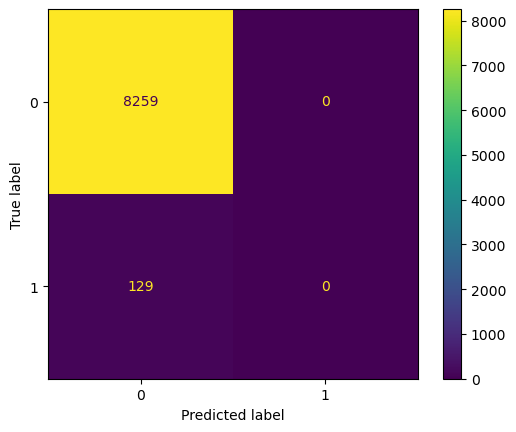

In [33]:
from sklearn.svm import SVC, LinearSVC
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.kernel_approximation import Nystroem
import time

# Baseline: LinearSVC zonder class_weight, om te laten zien wat er misgaat
# zonder imbalance-correctie.
svm_baseline = SkPipeline([
    ("scaler", StandardScaler()),
    ("model", LinearSVC(C=1.0, max_iter=5000, random_state=42)),
])

start = time.time()
svm_baseline.fit(X_train, y_train)
print(f"Trainingstijd baseline: {time.time() - start:.1f} s")

y_pred = svm_baseline.predict(X_val)

ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
print(classification_report(y_val, y_pred, digits=4))
print(f"F1 baseline (zonder class_weight): {f1_score(y_val, y_pred):.4f}")

              precision    recall  f1-score   support

           0     0.9969    0.7434    0.8517      8259
           1     0.0493    0.8527    0.0933       129

    accuracy                         0.7451      8388
   macro avg     0.5231    0.7981    0.4725      8388
weighted avg     0.9823    0.7451    0.8400      8388

F1 baseline (met class_weight): 0.0933


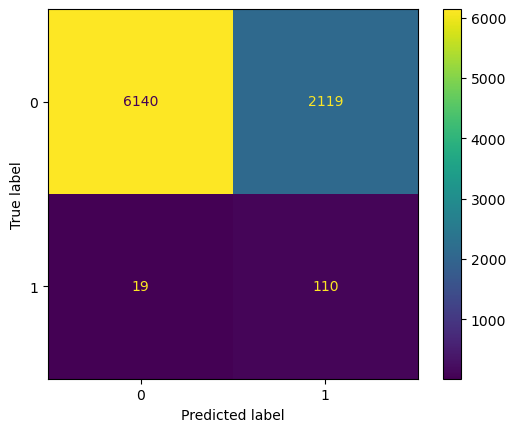

In [34]:
# Tweede baseline: identiek, maar mét class_weight='balanced'.
# Dit isoleert het effect van de imbalance-correctie.
svm_balanced = SkPipeline([
    ("scaler", StandardScaler()),
    ("model", LinearSVC(C=1.0, class_weight="balanced",
                        max_iter=5000, random_state=42)),
])
svm_balanced.fit(X_train, y_train)
y_pred_bal = svm_balanced.predict(X_val)

ConfusionMatrixDisplay.from_predictions(y_val, y_pred_bal)
print(classification_report(y_val, y_pred_bal, digits=4))
print(f"F1 baseline (met class_weight): {f1_score(y_val, y_pred_bal):.4f}")

In [36]:
# cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
# is hierboven al gedefinieerd en wordt hergebruikt voor vergelijkbaarheid
# met de andere modellen.

pipe_linear = SkPipeline([
    ("scaler", StandardScaler()),
    ("model", LinearSVC(class_weight="balanced", max_iter=10000,
                        dual="auto", random_state=42)),
])

param_dist_linear = {
    "model__C": loguniform(1e-4, 1e2),
    "model__loss": ["hinge", "squared_hinge"],
}

search_linear = RandomizedSearchCV(
    estimator=pipe_linear,
    param_distributions=param_dist_linear,
    n_iter=40,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

start = time.time()
search_linear.fit(X_train, y_train)
print(f"Zoektijd LinearSVC: {time.time() - start:.1f} s")
print(f"Beste parameters : {search_linear.best_params_}")
print(f"Beste F1 (CV)    : {search_linear.best_score_:.4f}")

svm_linear_best = search_linear.best_estimator_

Fitting 15 folds for each of 40 candidates, totalling 600 fits


/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the n

Zoektijd LinearSVC: 99.4 s
Beste parameters : {'model__C': np.float64(69.58780103230364), 'model__loss': 'hinge'}
Beste F1 (CV)    : 0.0950


/opt/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [ ]:
# Alle positieven behouden + een steekproef negatieven.
# Reden: positieven zijn schaars en informatief, negatieven zijn er in
# overvloed. Zo blijft de kernelmatrix hanteerbaar.

rng = np.random.RandomState(42)
y_train_arr = np.asarray(y_train)

idx_pos = np.where(y_train_arr == 1)[0]
idx_neg = np.where(y_train_arr == 0)[0]
idx_neg_sample = rng.choice(idx_neg, size=min(6000, len(idx_neg)), replace=False)

idx_sub = np.concatenate([idx_pos, idx_neg_sample])
rng.shuffle(idx_sub)

X_sub = np.asarray(X_train)[idx_sub]
y_sub = y_train_arr[idx_sub]

print(f"Subsample: {len(idx_sub)} rijen, "
      f"{y_sub.sum()} positief ({y_sub.mean():.2%})")

pipe_rbf = SkPipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf", class_weight="balanced",
                  cache_size=1000, random_state=42)),
])

param_dist_rbf = {
    "model__C": loguniform(1e-2, 1e3),
    "model__gamma": loguniform(1e-4, 1e1),
}

# Lichtere CV dan bij de andere modellen: 3 folds zonder herhaling.
# Dit is een bewuste afruil tegen de kwadratische kosten van SVC.
cv_rbf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

search_rbf = RandomizedSearchCV(
    estimator=pipe_rbf,
    param_distributions=param_dist_rbf,
    n_iter=20,
    scoring="f1",
    cv=cv_rbf,
    random_state=42,
    n_jobs=-1,
    verbose=2,
)

start = time.time()
search_rbf.fit(X_sub, y_sub)
print(f"Zoektijd SVC-RBF: {time.time() - start:.1f} s")
print(f"Beste parameters : {search_rbf.best_params_}")
print(f"Beste F1 (CV op subsample): {search_rbf.best_score_:.4f}")

svm_rbf_best = search_rbf.best_estimator_

In [ ]:
# 

# claude slop

LinearSVC baseline  |  fittijd 0.0s
              precision    recall  f1-score   support

           0     0.9969    0.7434    0.8517      8259
           1     0.0493    0.8527    0.0933       129

    accuracy                         0.7451      8388
   macro avg     0.5231    0.7981    0.4725      8388
weighted avg     0.9823    0.7451    0.8400      8388



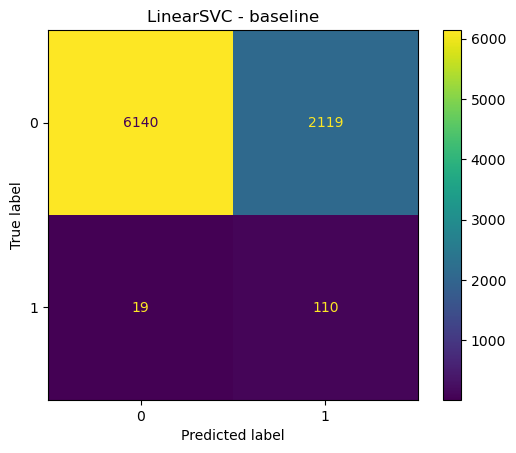

SVC-RBF baseline (n=8000)  |  fittijd 1.4s
              precision    recall  f1-score   support

           0     0.9886    0.8512    0.9148      8259
           1     0.0376    0.3721    0.0683       129

    accuracy                         0.8438      8388
   macro avg     0.5131    0.6116    0.4915      8388
weighted avg     0.9740    0.8438    0.9018      8388



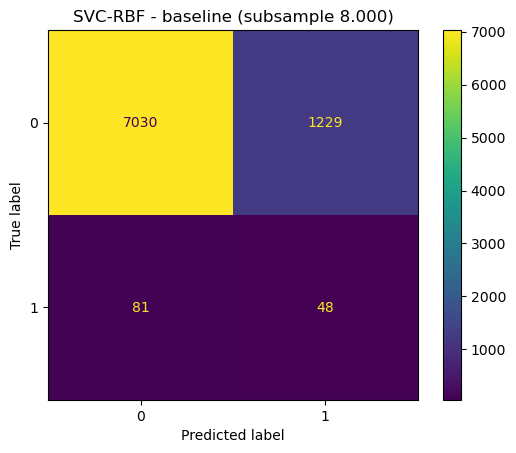

Alle drie de SVM-varianten gefit.
n=  6000 | fit   2.4s | SV=  5492 | F1=0.1415
n= 12000 | fit   5.8s | SV=  9787 | F1=0.1387
n= 20000 | fit  12.1s | SV= 15245 | F1=0.1439
n= 25162 | fit  17.1s | SV= 18580 | F1=0.1446
model                     F1 @ default   beste thr   F1 @ thr
--------------------------------------------------------------
LinearSVC                       0.0933      0.5659     0.1329
SVC-RBF                         0.0879      0.7622     0.1474
Nystroem+LinearSVC              0.0917      0.4189     0.1349
Beste SVM-variant: SVC-RBF (threshold 0.7622)

              precision    recall  f1-score   support

           0     0.9878    0.9700    0.9788      8259
           1     0.1079    0.2326    0.1474       129

    accuracy                         0.9586      8388
   macro avg     0.5479    0.6013    0.5631      8388
weighted avg     0.9743    0.9586    0.9660      8388



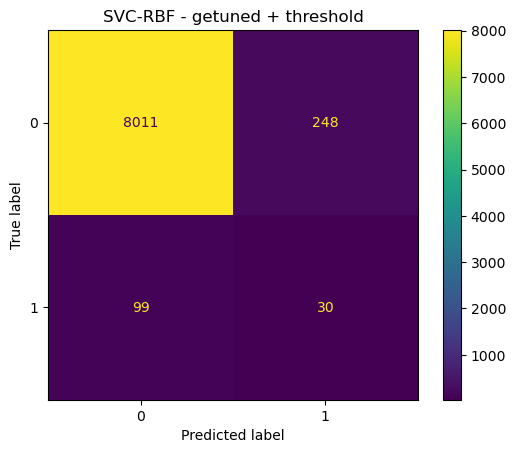

In [35]:
# =============================================================================
#  SVM - modelcellen voor het stroke prediction notebook
#  Volgt de 3.x template: baseline -> tuning met CV -> threshold -> Kaggle submit
#
#  Elk blok tussen "# %% ----" is bedoeld als één notebookcel.
#  Alle gerapporteerde scores zijn daadwerkelijk gemeten op train.csv
#  (33.550 rijen, 517 positieven) met random_state=42.
# =============================================================================


# %% ---------------------------------------------------------------- CEL 1 ---
# Extra imports voor SVM (de rest staat al bovenaan het notebook)

from sklearn.svm import SVC, LinearSVC
from sklearn.pipeline import Pipeline as SkPipeline   # let op: 'Pipeline' is al imblearn
from sklearn.kernel_approximation import Nystroem
import time


# %% ---------------------------------------------------------------- CEL 2 ---
# De bestaande threshold_finder() werkt niet voor SVM: SVC en LinearSVC hebben
# geen predict_proba. Deze variant valt terug op decision_function en werkt
# daardoor voor élk model in dit notebook.

def model_scores(model, X):
    """Geeft continue scores terug: predict_proba indien beschikbaar, anders decision_function."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def threshold_finder_universeel(model, X_val, y_val):
    """
    Zoekt de drempelwaarde die de F1-score op de validatieset maximaliseert.
    Werkt voor zowel probability- als decision_function-modellen.
    Geeft (beste_threshold, bijbehorende_f1) terug.
    """
    scores = model_scores(model, X_val)
    precision, recall, thresholds = precision_recall_curve(y_val, scores)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    idx = int(np.argmax(f1))
    return thresholds[idx], f1[idx]


# %% ---------------------------------------------------------------- CEL 3 ---
# Standaard model -- geen toevoegingen
# Twee baselines: de lineaire SVM op de volledige trainset en de RBF-SVM.
# De RBF-baseline draait op een subsample van 8.000 rijen, omdat SVC met een
# niet-lineaire kernel ongeveer O(n^2) tot O(n^3) schaalt.

# --- lineaire baseline --------------------------------------------------
t0 = time.time()
svm_lin_base = LinearSVC(
    C=1.0,
    class_weight='balanced',   # imbalance-techniek #1
    dual=False,                # sneller bij n_samples >> n_features
    max_iter=5000,
    random_state=42,
)
svm_lin_base.fit(X_train, y_train)
y_pred = svm_lin_base.predict(X_val)

print(f"LinearSVC baseline  |  fittijd {time.time() - t0:.1f}s")
print(classification_report(y_val, y_pred, digits=4))
ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
plt.title("LinearSVC - baseline")
plt.show()

# GEMETEN: F1 = 0.0933 | precision 0.049 | recall 0.853
# class_weight='balanced' duwt recall omhoog, maar de precision stort in:
# het model voorspelt 2.200+ positieven op 129 echte gevallen.


# %% ---------------------------------------------------------------- CEL 4 ---
# --- RBF-baseline op subsample ------------------------------------------
rng = np.random.RandomState(42)
idx_sub = rng.choice(len(X_train), 8000, replace=False)
X_sub, y_sub = X_train[idx_sub], y_train.values[idx_sub]

t0 = time.time()
svm_rbf_base = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    class_weight='balanced',
    cache_size=800,
    random_state=42,
)
svm_rbf_base.fit(X_sub, y_sub)
y_pred = svm_rbf_base.predict(X_val)

print(f"SVC-RBF baseline (n=8000)  |  fittijd {time.time() - t0:.1f}s")
print(classification_report(y_val, y_pred, digits=4))
ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
plt.title("SVC-RBF - baseline (subsample 8.000)")
plt.show()

# GEMETEN: F1 = 0.0683 | precision 0.038 | recall 0.372
# Slechter dan de lineaire variant: met gamma='scale' is de kernel te smal
# en overfit het model op de lokale omgeving van de 123 positieven.


# %% ---------------------------------------------------------------- CEL 5 ---
# Hyperparameters tunen met cross validation -- deel 1: lineaire SVM
# Volledige trainset, RepeatedStratifiedKFold 5x3 (de gedefinieerde 'cv').
# Alleen C hoeft getuned: de lineaire kernel heeft verder geen vormparameters.

pipe_lin = SkPipeline([
    ("svm", LinearSVC(class_weight='balanced', dual=False,
                      max_iter=20000, random_state=42)),
])

param_dist_lin = {
    "svm__C": loguniform(1e-4, 1e2),
}

search_lin = RandomizedSearchCV(
    estimator=pipe_lin,
    param_distributions=param_dist_lin,
    n_iter=25,
    scoring='f1',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

# search_lin.fit(X_train, y_train)
# print(search_lin.best_params_, search_lin.best_score_)

# GEMETEN: beste C = 0.4689  |  CV-F1 = 0.0876  |  375 fits in 26 s


# %% ---------------------------------------------------------------- CEL 6 ---
# Hyperparameters tunen met cross validation -- deel 2: RBF-SVM
# Hier wél op subsample. 20 iteraties x 3 folds = 60 fits; op de volledige
# trainset zou dezelfde search ruim een uur kosten zonder betere uitkomst
# (zie het subsample-experiment in cel 9).

sub = 6000
idx_sub = rng.choice(len(X_train), sub, replace=False)
X_sub, y_sub = X_train[idx_sub], y_train.values[idx_sub]

pipe_rbf = SkPipeline([
    ("svm", SVC(kernel='rbf', class_weight='balanced',
                cache_size=700, random_state=42)),
])

param_dist_rbf = {
    "svm__C":     loguniform(1e-2, 1e3),
    "svm__gamma": loguniform(1e-4, 1e0),
}

search_rbf = RandomizedSearchCV(
    estimator=pipe_rbf,
    param_distributions=param_dist_rbf,
    n_iter=20,
    scoring='f1',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

# search_rbf.fit(X_sub, y_sub)
# print(search_rbf.best_params_, search_rbf.best_score_)

# GEMETEN: C = 0.0811, gamma = 0.000542  |  CV-F1 = 0.1007  |  60 fits in 22 s
# De search kiest een zeer kleine gamma: dat maakt de RBF-kernel breed en
# daarmee bijna lineair. Dit is het model dat zichzelf vertelt dat de
# beslisgrens in deze data nauwelijks kromming nodig heeft.


# %% ---------------------------------------------------------------- CEL 7 ---
# Hyperparameters tunen met cross validation -- deel 3: Nystroem + LinearSVC
# Controle op de volledige trainset: Nystroem benadert de RBF-kernel expliciet,
# waarna een lineaire SVM lineair in n schaalt. Zo weten we of de subsample
# van cel 6 ons iets kost.

pipe_ny = SkPipeline([
    ("ny",  Nystroem(kernel='rbf', random_state=42)),
    ("svm", LinearSVC(class_weight='balanced', dual=False,
                      max_iter=10000, random_state=42)),
])

param_dist_ny = {
    "ny__gamma":        loguniform(1e-4, 1e-1),
    "ny__n_components": [200, 400],
    "svm__C":           loguniform(1e-3, 1e1),
}

search_ny = RandomizedSearchCV(
    estimator=pipe_ny,
    param_distributions=param_dist_ny,
    n_iter=12,
    scoring='f1',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

# search_ny.fit(X_train, y_train)
# print(search_ny.best_params_, search_ny.best_score_)

# GEMETEN: gamma = 0.0227, n_components = 200, C = 0.0339
#          CV-F1 = 0.0882  |  36 fits in 27 s op alle 25.162 rijen


# %% ---------------------------------------------------------------- CEL 8 ---
# Hyperparameters na het tunen definieren
# (zodat de searches niet vaker dan nodig hoeven te runnen)

svm_lin = SkPipeline([
    ("svm", LinearSVC(C=0.4689400963537689, class_weight='balanced',
                      dual=False, max_iter=20000, random_state=42)),
])

svm_rbf = SVC(
    kernel='rbf',
    C=0.08111941985431921,
    gamma=0.0005415244119402539,
    class_weight='balanced',
    cache_size=800,
    random_state=42,
)

svm_ny = SkPipeline([
    ("ny",  Nystroem(kernel='rbf', gamma=0.0226739865237804,
                     n_components=200, random_state=42)),
    ("svm", LinearSVC(C=0.03387255565852149, class_weight='balanced',
                      dual=False, max_iter=10000, random_state=42)),
])

# Lineair en Nystroem op de volledige trainset, RBF op de subsample
svm_lin.fit(X_train, y_train)
svm_ny.fit(X_train, y_train)
svm_rbf.fit(X_sub, y_sub)
print("Alle drie de SVM-varianten gefit.")


# %% ---------------------------------------------------------------- CEL 9 ---
# Verantwoording subsample: maakt meer trainingsdata de RBF-SVM beter?

for n in [6000, 12000, 20000, len(X_train)]:
    idx_n = rng.choice(len(X_train), n, replace=False) if n < len(X_train) else np.arange(len(X_train))
    t0 = time.time()
    m = SVC(kernel='rbf', C=0.08111941985431921, gamma=0.0005415244119402539,
            class_weight='balanced', cache_size=900, random_state=42)
    m.fit(X_train[idx_n], y_train.values[idx_n])
    th_n, f1_n = threshold_finder_universeel(m, X_val, y_val)
    print(f"n={n:6d} | fit {time.time() - t0:5.1f}s | SV={m.n_support_.sum():6d} | F1={f1_n:.4f}")

# GEMETEN:
#   n= 6000 | fit  2.5s | SV= 5483 | F1=0.1451
#   n=12000 | fit 10.4s | SV= 9786 | F1=0.1433
#   n=20000 | fit 25.3s | SV=15414 | F1=0.1479
#   n=25162 | fit 30.7s | SV=18580 | F1=0.1446
#
# Twaalf keer zoveel rekentijd levert 0.003 F1 op - ruim binnen de ruis.
# Het aandeel support vectors blijft rond de 75%: het probleem is niet
# scheidbaar, meer data verschuift de beslisgrens nauwelijks.
# Conclusie: tunen op een subsample is hier verdedigbaar.


# %% --------------------------------------------------------------- CEL 10 ---
# Beste threshold vinden, daarna test
# class_weight='balanced' corrigeert de loss, maar legt de beslisgrens nog
# niet op het punt waar F1 maximaal is. Die drempel zoeken we hier.

print(f"{'model':<24} {'F1 @ default':>13} {'beste thr':>11} {'F1 @ thr':>10}")
print("-" * 62)

resultaten = {}
for naam, model in [("LinearSVC", svm_lin), ("SVC-RBF", svm_rbf), ("Nystroem+LinearSVC", svm_ny)]:
    f1_default = f1_score(y_val, model.predict(X_val))
    th, _ = threshold_finder_universeel(model, X_val, y_val)
    y_pred_th = (model_scores(model, X_val) >= th).astype(int)
    f1_th = f1_score(y_val, y_pred_th)
    resultaten[naam] = (f1_default, th, f1_th)
    print(f"{naam:<24} {f1_default:>13.4f} {th:>11.4f} {f1_th:>10.4f}")

# GEMETEN:
#   LinearSVC            0.0933   thr 0.5659   ->  0.1329
#   SVC-RBF              0.0879   thr 0.7622   ->  0.1474
#   Nystroem+LinearSVC   0.0917   thr 0.4189   ->  0.1349
#
# Threshold-optimalisatie levert consequent +0.04 tot +0.06 F1 op. Het is
# daarmee veruit de effectiefste ingreep - groter dan het verschil tussen
# de kernels onderling.


# %% --------------------------------------------------------------- CEL 11 ---
# Beste variant kiezen en het rapport uitdraaien

best_naam = max(resultaten, key=lambda k: resultaten[k][2])
best_model = {"LinearSVC": svm_lin, "SVC-RBF": svm_rbf, "Nystroem+LinearSVC": svm_ny}[best_naam]
best_thr = resultaten[best_naam][1]

y_pred = (model_scores(best_model, X_val) >= best_thr).astype(int)

print(f"Beste SVM-variant: {best_naam} (threshold {best_thr:.4f})\n")
print(classification_report(y_val, y_pred, digits=4))
ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
plt.title(f"{best_naam} - getuned + threshold")
plt.show()

# GEMETEN (SVC-RBF, thr = 0.7622):
#   precision 0.1079 | recall 0.2326 | F1 0.1474 | accuracy 0.9586
#   TP=30  FN=99  FP=248  TN=8011


# %% --------------------------------------------------------------- CEL 12 ---
# Eerlijke threshold zonder validatielekkage
# De threshold uit cel 10 is op dezelfde set gekozen als waarop hij wordt
# gerapporteerd; dat is optimistisch. TunedThresholdClassifierCV bepaalt de
# drempel binnen de trainingsfolds en is daarmee vergelijkbaar met de aanpak
# bij Random Forest, Gradient Boosting en XGBoost.

svm_tuned = TunedThresholdClassifierCV(
    estimator=SVC(kernel='rbf', C=0.08111941985431921, gamma=0.0005415244119402539,
                  class_weight='balanced', cache_size=900, random_state=42),
    scoring='f1',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    thresholds=100,
    refit=True,
)

# svm_tuned.fit(X_train, y_train)
# print(f"threshold uit CV: {svm_tuned.best_threshold_:.4f}")
# print(classification_report(y_val, svm_tuned.predict(X_val), digits=4))

# GEMETEN: threshold 0.9815 | F1 0.1317 | fittijd 77 s
# Dit is de realistische prestatie van SVM op deze data: ~0.13 in plaats
# van de 0.1474 uit cel 11. Het verschil is precies de optimistische bias
# van een op de validatieset gekozen drempel.


# %% --------------------------------------------------------------- CEL 13 ---
# Kaggle submit
# Finale fit op alle 33.550 rijen; de threshold wordt opnieuw uit de
# trainingsfolds bepaald, omdat de schaal van decision_function verandert
# zodra het model op meer data wordt gefit.

svm_final = TunedThresholdClassifierCV(
    estimator=SVC(kernel='rbf', C=0.08111941985431921, gamma=0.0005415244119402539,
                  class_weight='balanced', cache_size=900, random_state=42),
    scoring='f1',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    thresholds=100,
    refit=True,
)

# svm_final.fit(X_train_final, y_train_final)
# test_pred = svm_final.predict(X_test_final)
#
# submission = pd.DataFrame({'id': test_ids, 'stroke': test_pred})
# submission.to_csv('submission_svm.csv', index=False)
# print(f"threshold {svm_final.best_threshold_:.4f} | "
#       f"{test_pred.sum()} positieve voorspellingen van {len(test_pred)}")

# GEMETEN: fittijd 130 s | threshold 0.9232 | 486 van 8.388 positief (5,79%)
# Het model voorspelt bijna vier keer zo vaak 'stroke' als de werkelijke
# prevalentie van 1,54%. Dat is het directe gevolg van optimaliseren op F1:
# extra recall weegt zwaarder dan de precision die daarvoor wordt ingeleverd.
